In [1]:
import os 
import numpy as np

data_path='PetImages'  # dataset eka thiyena path eka define kranava

categories=os.listdir(data_path)   #path eke thiyena file,folder names genath dei 
print(categories)
labels=np.arange(len(categories))
print(labels)
label_dict=dict(zip(categories,labels)) # pytho dictionary ekk hadima
print(label_dict)

['Cat', 'Dog']
[0 1]
{'Cat': np.int64(0), 'Dog': np.int64(1)}


In [2]:
import cv2

img_size=50

data=[]
target=[]

for category in categories:                    #me loop eka 2parai run venne
    
    category_path=os.path.join(data_path,category) # PetImages/Cat,PetImages/Dog atule path eka ganima
    #print(img_path)
    img_names=os.listdir(category_path)       #path eke thiyena file,folder names genath dei 
    #print(img_names)
    for img_name in img_names:                                                #me loop eka 12500 parak run vei
        img_path=os.path.join(category_path,img_name)
        #print(img_path)
        try:
            img=cv2.imread(img_path)                   #imread vlin image eka load kara gani     #image path eken image eka load karaganna puluvn
            img=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)   #cat/dog color eka matha depend nove.e nisa gray use kla haka.gray image vlin nn eka train venna yana velava ituru karai
            img=cv2.resize(img,(img_size,img_size))    #features(pixels) samana vimata image size eka samana kara ganna one
            #image size eka loku venna loku venna nn eka train venna yana time eka vadiy

            data.append(img)
            target.append(label_dict[category])
        except Exception as e:
            print(img_path,e)

PetImages\Cat\10404.jpg OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'

PetImages\Cat\666.jpg OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'

PetImages\Dog\11702.jpg OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'



In [3]:
data_new=np.array(data)
target_new=np.array(target)

In [4]:
print(data_new.shape)
print(target_new.shape)

(24997, 50, 50)
(24997,)


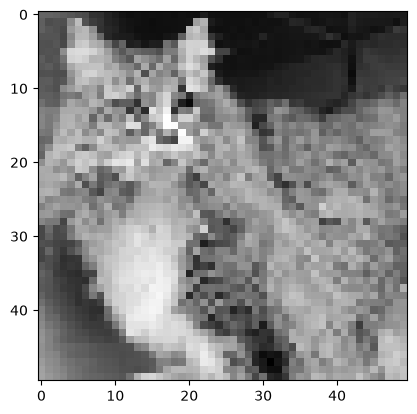

In [5]:
from matplotlib import pyplot as plt

plt.imshow(data[100],cmap='gray')        #data set eka balima

In [6]:
target_new[100]

np.int64(0)

In [7]:
print(data_new.shape)
print(data_new.shape[0],data_new.shape[1],data_new.shape[2])

(24997, 50, 50)
24997 50 50


In [8]:
data_new=data_new.reshape(data_new.shape[0],data_new.shape[1],data_new.shape[2],1) # converting to 4D, CNN needs 4D input
print(data_new.shape)

(24997, 50, 50, 1)


In [9]:
data_new[10] # 11 veni image eka array vidiyt

array([[[146],
        [148],
        [153],
        ...,
        [167],
        [164],
        [ 83]],

       [[147],
        [152],
        [152],
        ...,
        [167],
        [165],
        [ 93]],

       [[151],
        [154],
        [155],
        ...,
        [166],
        [168],
        [109]],

       ...,

       [[182],
        [201],
        [208],
        ...,
        [250],
        [249],
        [242]],

       [[204],
        [205],
        [212],
        ...,
        [245],
        [243],
        [249]],

       [[187],
        [208],
        [212],
        ...,
        [252],
        [249],
        [247]]], shape=(50, 50, 1), dtype=uint8)

In [10]:
data_new=data_new/255 #normalizing/ Scaling            #hama image ekema ,hama pixcel value ekkma 255 bedai

from keras import utils

target_new=utils.to_categorical(target_new)

In [11]:
target_new

array([[1., 0.],
       [1., 0.],
       [1., 0.],
       ...,
       [0., 1.],
       [0., 1.],
       [0., 1.]], shape=(24997, 2))

In [12]:
data_new[10] # normalizing/ Scaling  vlt pasu 10 veni image eka array vidiyt

array([[[0.57254902],
        [0.58039216],
        [0.6       ],
        ...,
        [0.65490196],
        [0.64313725],
        [0.3254902 ]],

       [[0.57647059],
        [0.59607843],
        [0.59607843],
        ...,
        [0.65490196],
        [0.64705882],
        [0.36470588]],

       [[0.59215686],
        [0.60392157],
        [0.60784314],
        ...,
        [0.65098039],
        [0.65882353],
        [0.42745098]],

       ...,

       [[0.71372549],
        [0.78823529],
        [0.81568627],
        ...,
        [0.98039216],
        [0.97647059],
        [0.94901961]],

       [[0.8       ],
        [0.80392157],
        [0.83137255],
        ...,
        [0.96078431],
        [0.95294118],
        [0.97647059]],

       [[0.73333333],
        [0.81568627],
        [0.83137255],
        ...,
        [0.98823529],
        [0.97647059],
        [0.96862745]]], shape=(50, 50, 1))

In [13]:
np.save('data',data_new)             #data,target  np array ekk lesa save kri
np.save('target',target_new)
